In [93]:
import numpy as np
import pandas as pd

from pathlib import Path

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error


SEED = 42

BASE = Path(
    "/kaggle/input/datasets/mishanyaz000/"
    "metro-hack-dataset/dataset"
)

LABELS_PATH = BASE / "labels/labels_train.csv"
SCHEDULE_PATH = BASE / "train/schedule.csv"

TARGET = "target_delay_s"

In [94]:
labels = pd.read_csv(
    LABELS_PATH,
    low_memory=False
)

schedule = pd.read_csv(
    SCHEDULE_PATH,
    low_memory=False
)

print("labels:", labels.shape)
print("schedule:", schedule.shape)

labels: (4434, 8)
schedule: (16674, 8)


preprocessing


In [95]:
def preprocess_data(labels, schedule):
    labels = labels.copy()
    schedule = schedule.copy()

    labels["T"] = pd.to_datetime(
        labels["T"],
        errors="coerce"
    )

    labels["target_time_begin"] = pd.to_datetime(
        labels["target_time_begin"],
        errors="coerce"
    )

    schedule["time_begin"] = pd.to_datetime(
        schedule["time_begin"],
        errors="coerce"
    )

    schedule["time_fact_begin"] = pd.to_datetime(
        schedule["time_fact_begin"],
        errors="coerce"
    )

    schedule["stop_delay_s"] = (
        schedule["time_fact_begin"]
        - schedule["time_begin"]
    ).dt.total_seconds()

    labels = labels.sort_values("T").reset_index(drop=True)

    schedule = schedule.sort_values(
        ["tr_id", "time_fact_begin"]
    ).reset_index(drop=True)

    return labels, schedule


labels, schedule = preprocess_data(
    labels,
    schedule
)

print("T:", labels["T"].min(), "→", labels["T"].max())

print(
    "Schedule:",
    schedule["time_fact_begin"].min(),
    "→",
    schedule["time_fact_begin"].max()
)

T: 2026-01-06 02:10:00 → 2026-01-07 00:25:00
Schedule: 2026-01-06 02:12:06.876587200 → 2026-01-07 04:21:00


Time features

In [96]:
def build_time_features(df):
    df = df.copy()

    df["hour"] = df["T"].dt.hour
    df["minute"] = df["T"].dt.minute

    df["minute_of_day"] = (
        df["hour"] * 60
        + df["minute"]
    )

    df["day_of_week"] = df["T"].dt.dayofweek

    df["is_weekend"] = (
        df["day_of_week"] >= 5
    ).astype(int)

    df["sin_time"] = np.sin(
        2 * np.pi * df["minute_of_day"] / 1440
    )

    df["cos_time"] = np.cos(
        2 * np.pi * df["minute_of_day"] / 1440
    )

    df["target_hour"] = (
        df["target_time_begin"].dt.hour
    )

    df["target_minute_of_day"] = (
        df["target_time_begin"].dt.hour * 60
        + df["target_time_begin"].dt.minute
    )

    df["forecast_horizon_s"] = (
        df["target_time_begin"] - df["T"]
    ).dt.total_seconds()

    return df

Current delay features

In [97]:
def build_current_delay_features(df):
    df = df.copy()

    df["abs_cur_dev"] = (
        df["cur_dev_s"].abs()
    )

    df["is_late_now"] = (
        df["cur_dev_s"] > 0
    ).astype(int)

    df["is_early_now"] = (
        df["cur_dev_s"] < 0
    ).astype(int)

    return df

Schedule history

In [98]:
def build_schedule_history_features(
    df,
    schedule,
):
    df = df.copy()

    schedule_by_trip = {
        tr_id: group.sort_values("time_fact_begin")
        for tr_id, group
        in schedule.groupby("tr_id")
    }

    rows = []

    for _, row in df.iterrows():
        trip = schedule_by_trip.get(row["tr_id"])

        if trip is None:
            rows.append({
                "last_stop_delay": np.nan,
                "prev_stop_delay": np.nan,
                "mean_delay_last_3": np.nan,
                "mean_delay_last_5": np.nan,
                "std_delay_last_5": np.nan,
                "delay_trend": np.nan,
                "stops_passed": 0,
                "seconds_since_last_stop": np.nan,
            })

            continue

        history = trip[
            trip["time_fact_begin"] <= row["T"]
        ]

        if history.empty:
            rows.append({
                "last_stop_delay": np.nan,
                "prev_stop_delay": np.nan,
                "mean_delay_last_3": np.nan,
                "mean_delay_last_5": np.nan,
                "std_delay_last_5": np.nan,
                "delay_trend": np.nan,
                "stops_passed": 0,
                "seconds_since_last_stop": np.nan,
            })

            continue

        delays = history["stop_delay_s"]

        last_delay = delays.iloc[-1]

        prev_delay = (
            delays.iloc[-2]
            if len(delays) >= 2
            else np.nan
        )

        delay_trend = (
            last_delay - prev_delay
            if len(delays) >= 2
            else np.nan
        )

        last_fact_time = (
            history["time_fact_begin"].iloc[-1]
        )

        seconds_since_last_stop = (
            row["T"] - last_fact_time
        ).total_seconds()

        rows.append({
            "last_stop_delay":
                last_delay,

            "prev_stop_delay":
                prev_delay,

            "mean_delay_last_3":
                delays.tail(3).mean(),

            "mean_delay_last_5":
                delays.tail(5).mean(),

            "std_delay_last_5":
                delays.tail(5).std(),

            "delay_trend":
                delay_trend,

            "stops_passed":
                len(history),

            "seconds_since_last_stop":
                seconds_since_last_stop,
        })

    history_features = pd.DataFrame(
        rows,
        index=df.index
    )

    return pd.concat(
        [df, history_features],
        axis=1
    )

Schedule target features

In [99]:
def build_schedule_target_features(
    df,
    schedule,
):
    df = df.copy()

    schedule_by_trip = {
        tr_id: group.sort_values("time_begin")
        for tr_id, group
        in schedule.groupby("tr_id")
    }

    values = []

    for _, row in df.iterrows():
        trip = schedule_by_trip.get(row["tr_id"])

        if trip is None:
            values.append(np.nan)
            continue

        target = trip[
            trip["tt_action_item_id"]
            == row["target_stop_id"]
        ]

        if target.empty:
            values.append(np.nan)
            continue

        target_time = (
            target["time_begin"].iloc[0]
        )

        stops_to_target = trip[
            (trip["time_begin"] > row["T"])
            &
            (trip["time_begin"] <= target_time)
        ]["tt_action_item_id"].nunique()

        values.append(stops_to_target)

    df["stops_to_target"] = values

    return df

дополнительные безопасные schedule-фичи

In [100]:
def build_schedule_derived_features(df):
    df = df.copy()

    df["has_schedule_history"] = (
        df["last_stop_delay"].notna()
    ).astype(int)

    df["seconds_since_last_stop_clipped"] = (
        df["seconds_since_last_stop"]
        .clip(upper=600)
    )

    return df

Единый Mishgan feature pipeline

In [101]:
def build_mishgan_features(
    labels,
    schedule,
):
    features = labels.copy()

    features = build_time_features(
        features
    )

    features = build_current_delay_features(
        features
    )

    features = build_schedule_history_features(
        features,
        schedule
    )

    features = build_schedule_target_features(
        features,
        schedule
    )

    features = build_schedule_derived_features(
        features
    )

    return features

In [102]:
features = build_mishgan_features(
    labels,
    schedule
)

print("Features shape:", features.shape)

display(features.head())

Features shape: (4434, 32)


,sample_id,tr_id,T,target_stop_id,target_time_begin,cur_dev_s,target_delay_s,target_class,hour,minute,...,prev_stop_delay,mean_delay_last_3,mean_delay_last_5,std_delay_last_5,delay_trend,stops_passed,seconds_since_last_stop,stops_to_target,has_schedule_history,seconds_since_last_stop_clipped
0,122048_1767665400,122048,2026-01-06 02:10:00,53699018679,2026-01-06 02:22:00.000000000,0.0,-25.0,ontime,2,10,...,NaN,NaN,NaN,NaN,NaN,0,NaN,1,0,NaN
1,9000014_1767665400,9000014,2026-01-06 02:10:00,10400473,2026-01-06 02:20:56.876587200,0.0,7.0,ontime,2,10,...,NaN,NaN,NaN,NaN,NaN,0,NaN,6,0,NaN
2,9000001_1767665400,9000001,2026-01-06 02:10:00,9100456,2026-01-06 02:23:06.862763477,0.0,31.0,ontime,2,10,...,NaN,NaN,NaN,NaN,NaN,0,NaN,1,0,NaN
3,122048_1767665700,122048,2026-01-06 02:15:00,53699018678,2026-01-06 02:26:00.000000000,0.0,0.0,ontime,2,15,...,NaN,NaN,NaN,NaN,NaN,0,NaN,5,0,NaN
4,9000014_1767665700,9000014,2026-01-06 02:15:00,10400660,2026-01-06 02:25:56.876587200,-20.0,49.0,ontime,2,15,...,10.0,-5.0,-5.0,21.213203,-30.0,2,143.123412,8,1,143.123412


In [103]:
FEATURE_COLS = [
    # Categorical
    "tr_id",
    "target_stop_id",

    # Time
    "hour",
    "minute",
    "minute_of_day",
    "day_of_week",
    "is_weekend",
    "sin_time",
    "cos_time",

    # Target time
    "target_hour",
    "target_minute_of_day",
    "forecast_horizon_s",

    # Current delay
    "cur_dev_s",
    "abs_cur_dev",
    "is_late_now",
    "is_early_now",

    # Schedule
    "has_schedule_history",
    "last_stop_delay",
    "prev_stop_delay",
    "mean_delay_last_3",
    "mean_delay_last_5",
    "std_delay_last_5",
    "delay_trend",
    "stops_passed",
    "seconds_since_last_stop",
    "seconds_since_last_stop_clipped",
    "stops_to_target",
]

CAT_FEATURES = [
    "tr_id",
    "target_stop_id",
]

print("Количество фич:", len(FEATURE_COLS))

print("\nПропуски:")
print(
    features[FEATURE_COLS]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Количество фич: 27

Пропуски:
std_delay_last_5                   107
delay_trend                        107
prev_stop_delay                    107
seconds_since_last_stop             98
seconds_since_last_stop_clipped     98
mean_delay_last_5                   98
mean_delay_last_3                   98
last_stop_delay                     98
tr_id                                0
target_stop_id                       0
hour                                 0
target_minute_of_day                 0
target_hour                          0
cos_time                             0
sin_time                             0
is_weekend                           0
day_of_week                          0
minute_of_day                        0
minute                               0
is_early_now                         0
has_schedule_history                 0
abs_cur_dev                          0
is_late_now                          0
cur_dev_s                            0
forecast_horizon_s                

VALIDATION

temporal split

In [104]:
unique_times = np.sort(
    features["T"].unique()
)

split_idx = int(
    len(unique_times) * 0.8
)

split_time = unique_times[split_idx]

train_mask = (
    features["T"] < split_time
)

val_mask = (
    features["T"] >= split_time
)

train_df = (
    features.loc[train_mask].copy()
)

val_df = (
    features.loc[val_mask].copy()
)

print("Split:", split_time)

print(
    "Train:",
    len(train_df),
    train_df["T"].min(),
    "→",
    train_df["T"].max(),
)

print(
    "Validation:",
    len(val_df),
    val_df["T"].min(),
    "→",
    val_df["T"].max(),
)

Split: 2026-01-06T20:00:00.000000000
Train: 3875 2026-01-06 02:10:00 → 2026-01-06 19:55:00
Validation: 559 2026-01-06 20:00:00 → 2026-01-07 00:25:00


метрики

In [105]:
def wape_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    denominator = np.sum(y_true)

    if denominator <= 0:
        return 0.0

    error = np.sum(
        np.abs(y_true - y_pred)
    )

    return max(
        0.0,
        1.0 - error / denominator
    )


def evaluate_model(
    y_true,
    y_pred,
):
    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    wape = wape_score(
        y_true,
        y_pred
    )

    return {
        "MAE": mae,
        "WAPE": wape,
    }

MODEL

подготовка данных

In [106]:
X_train = train_df[
    FEATURE_COLS
].copy()

X_val = val_df[
    FEATURE_COLS
].copy()

y_train = train_df[
    TARGET
].copy()

y_val = val_df[
    TARGET
].copy()

for col in CAT_FEATURES:
    X_train[col] = (
        X_train[col].astype(str)
    )

    X_val[col] = (
        X_val[col].astype(str)
    )

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (3875, 27)
X_val: (559, 27)


baseline cur_dev_s

In [107]:
baseline_pred = (
    val_df["cur_dev_s"].values
)

baseline_metrics = evaluate_model(
    y_val,
    baseline_pred
)

print("Current-delay baseline")
print(baseline_metrics)

Current-delay baseline
{'MAE': 78.65652951699464, 'WAPE': 0.0}


CatBoost V1

In [108]:
model = CatBoostRegressor(
    loss_function="MAE",

    iterations=1000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=5,

    random_seed=SEED,

    allow_writing_files=False,
)

model.fit(
    X_train,
    y_train,

    cat_features=CAT_FEATURES,

    eval_set=(
        X_val,
        y_val,
    ),

    early_stopping_rounds=100,

    verbose=100,
)

0:	learn: 94.7273874	test: 83.5479419	best: 83.5479419 (0)	total: 8.72ms	remaining: 8.71s
100:	learn: 67.7998726	test: 68.8864018	best: 65.7033209 (55)	total: 654ms	remaining: 5.82s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 65.70332093
bestIteration = 55

Shrink model to first 56 iterations.


CatBoostRegressor(allow_writing_files=False, depth=6, iterations=1000, l2_leaf_reg=5, learning_rate=0.03, loss_function='MAE', random_seed=42)

результат

In [109]:
val_pred = model.predict(
    X_val
)

model_metrics = evaluate_model(
    y_val,
    val_pred
)

print("Baseline:")
print(baseline_metrics)

print("\nMishgan V1:")
print(model_metrics)

print(
    "\nBest iteration:",
    model.get_best_iteration()
)

Baseline:
{'MAE': 78.65652951699464, 'WAPE': 0.0}

Mishgan V1:
{'MAE': 65.70332193188494, 'WAPE': np.float64(0.07334030629686683)}

Best iteration: 55


importance

In [110]:
importance = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance":
        model.get_feature_importance(),
})

importance = importance.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

display(
    importance.head(20)
)

,feature,importance
0,stops_to_target,22.568653
1,cur_dev_s,20.908501
2,abs_cur_dev,13.231513
3,tr_id,10.500436
4,last_stop_delay,6.075532
5,stops_passed,3.516001
6,seconds_since_last_stop_clipped,3.068807
7,cos_time,2.819287
8,seconds_since_last_stop,2.756550
9,sin_time,2.358935


**Журнал 1**

In [111]:
experiments = pd.DataFrame([
    {
        "version": "baseline",
        "description": "cur_dev_s only",
        "MAE": baseline_metrics["MAE"],
        "WAPE": baseline_metrics["WAPE"],
    },
    {
        "version": "M1",
        "description":
            "time + current delay + schedule",
        "MAE": model_metrics["MAE"],
        "WAPE": model_metrics["WAPE"],
    },
])

display(
    experiments.sort_values("MAE")
)

,version,description,MAE,WAPE
1,M1,time + current delay + schedule,65.703322,0.07334
0,baseline,cur_dev_s only,78.656530,0.00000


Advanced schedule history
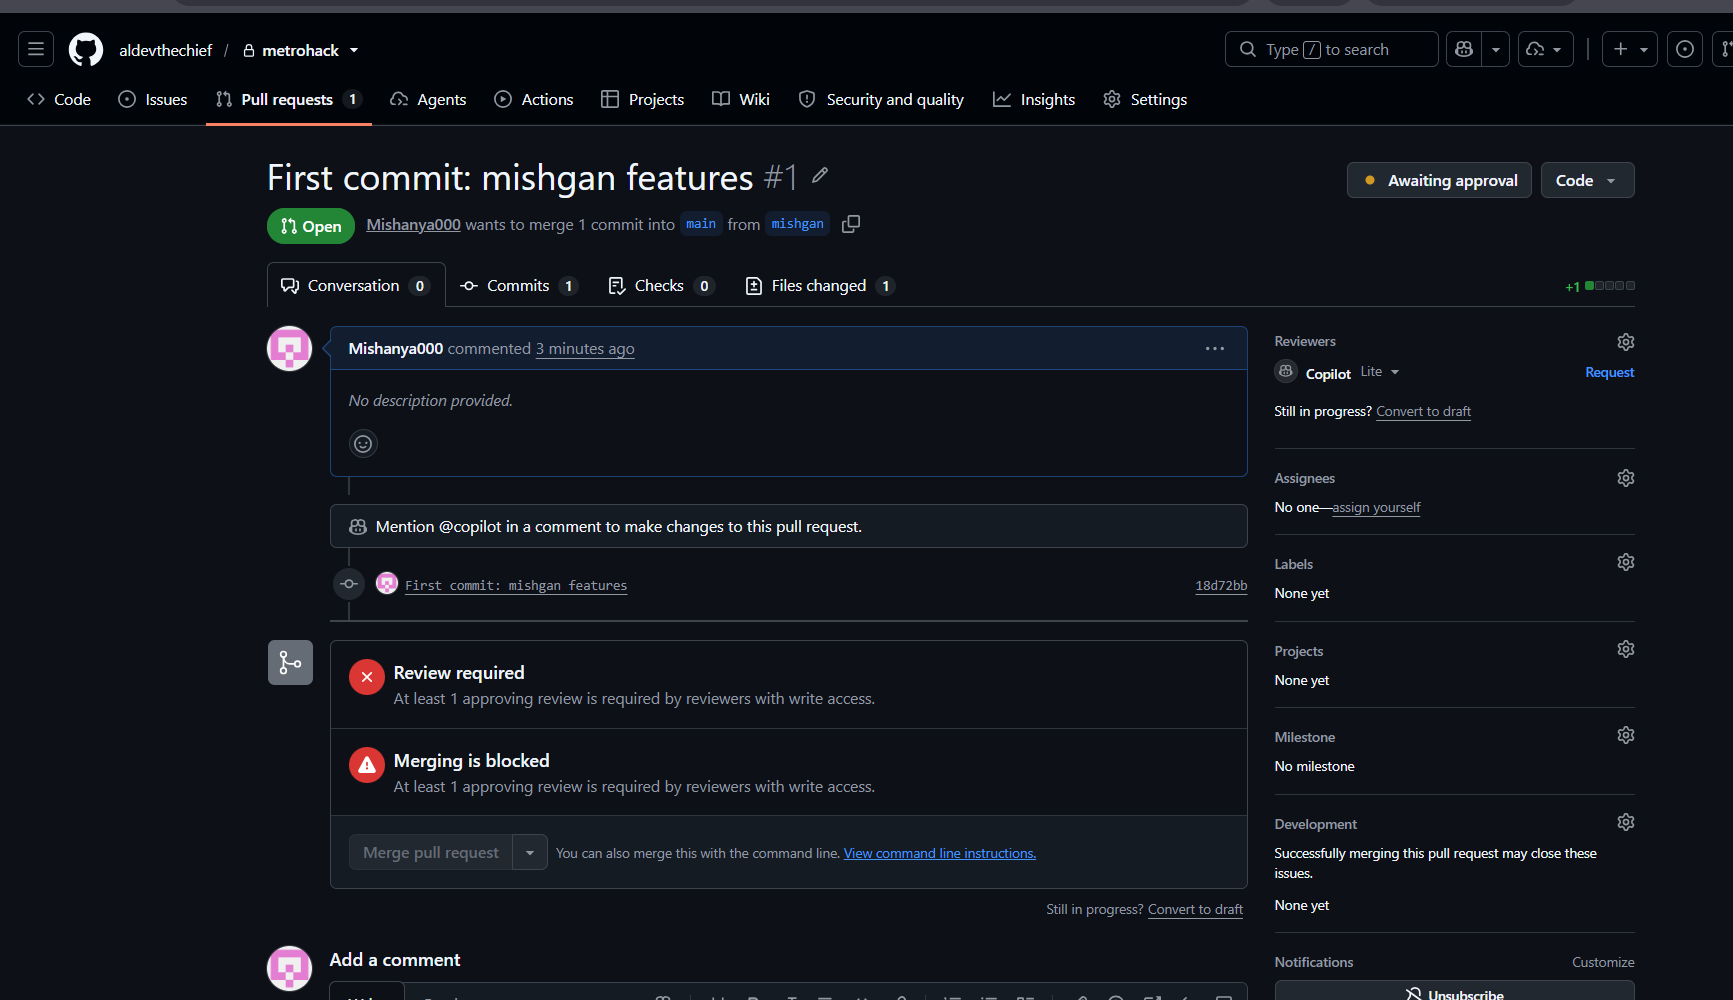

In [112]:
def build_advanced_schedule_features(
    df,
    schedule,
):
    df = df.copy()

    schedule_by_trip = {
        tr_id: group.sort_values("time_fact_begin")
        for tr_id, group in schedule.groupby("tr_id")
    }

    rows = []

    for _, row in df.iterrows():
        trip = schedule_by_trip.get(row["tr_id"])

        if trip is None:
            rows.append({
                "delay_change_last_3": np.nan,
                "delay_slope_last_3": np.nan,
                "delay_range_last_3": np.nan,
                "delay_range_last_5": np.nan,
            })
            continue

        history = trip[
            trip["time_fact_begin"] <= row["T"]
        ]

        delays = (
            history["stop_delay_s"]
            .dropna()
            .to_numpy()
        )

        if len(delays) >= 3:
            last_3 = delays[-3:]

            delay_change_last_3 = (
                last_3[-1] - last_3[0]
            )

            delay_slope_last_3 = np.polyfit(
                np.arange(len(last_3)),
                last_3,
                1,
            )[0]

            delay_range_last_3 = (
                np.max(last_3)
                - np.min(last_3)
            )
        else:
            delay_change_last_3 = np.nan
            delay_slope_last_3 = np.nan
            delay_range_last_3 = np.nan

        if len(delays) >= 2:
            last_5 = delays[-5:]

            delay_range_last_5 = (
                np.max(last_5)
                - np.min(last_5)
            )
        else:
            delay_range_last_5 = np.nan

        rows.append({
            "delay_change_last_3":
                delay_change_last_3,

            "delay_slope_last_3":
                delay_slope_last_3,

            "delay_range_last_3":
                delay_range_last_3,

            "delay_range_last_5":
                delay_range_last_5,
        })

    advanced = pd.DataFrame(
        rows,
        index=df.index,
    )

    return pd.concat(
        [df, advanced],
        axis=1,
    )

строим M2

In [113]:
features_m2 = build_advanced_schedule_features(
    features,
    schedule,
)

ADVANCED_SCHEDULE_COLS = [
    "delay_change_last_3",
    "delay_slope_last_3",
    "delay_range_last_3",
    "delay_range_last_5",
]

FEATURE_COLS_M2 = (
    FEATURE_COLS
    + ADVANCED_SCHEDULE_COLS
)

print(
    "M1 features:",
    len(FEATURE_COLS)
)

print(
    "M2 features:",
    len(FEATURE_COLS_M2)
)

print("\nНовые фичи:")

display(
    features_m2[
        ADVANCED_SCHEDULE_COLS
    ].describe().T
)

print("\nПропуски:")

print(
    features_m2[
        ADVANCED_SCHEDULE_COLS
    ].isna().sum()
)

M1 features: 27
M2 features: 31

Новые фичи:


,count,mean,std,min,25%,50%,75%,max
delay_change_last_3,4316.0,-6.140176,78.286363,-947.0,-39.250,-1.0,33.0,627.0
delay_slope_last_3,4316.0,-3.070088,39.143181,-473.5,-19.625,-0.5,16.5,313.5
delay_range_last_3,4316.0,63.958063,63.572583,0.0,29.000,50.0,79.0,947.0
delay_range_last_5,4327.0,99.106771,79.749128,0.0,52.000,81.0,123.0,954.0



Пропуски:
delay_change_last_3    118
delay_slope_last_3     118
delay_range_last_3     118
delay_range_last_5     107
dtype: int64


temporal split

In [114]:
train_m2 = features_m2[
    features_m2["T"] < split_time
].copy()

val_m2 = features_m2[
    features_m2["T"] >= split_time
].copy()

X_train_m2 = train_m2[
    FEATURE_COLS_M2
].copy()

X_val_m2 = val_m2[
    FEATURE_COLS_M2
].copy()

y_train_m2 = train_m2[
    TARGET
].copy()

y_val_m2 = val_m2[
    TARGET
].copy()

for col in CAT_FEATURES:
    X_train_m2[col] = (
        X_train_m2[col].astype(str)
    )

    X_val_m2[col] = (
        X_val_m2[col].astype(str)
    )

print("Train:", X_train_m2.shape)
print("Validation:", X_val_m2.shape)

Train: (3875, 31)
Validation: (559, 31)


CatBoost M2

In [115]:
model_m2 = CatBoostRegressor(
    loss_function="MAE",

    iterations=1000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=5,

    random_seed=SEED,

    allow_writing_files=False,
)

model_m2.fit(
    X_train_m2,
    y_train_m2,

    cat_features=CAT_FEATURES,

    eval_set=(
        X_val_m2,
        y_val_m2,
    ),

    early_stopping_rounds=100,

    verbose=100,
)

0:	learn: 94.7971913	test: 83.6883533	best: 83.6883533 (0)	total: 10.4ms	remaining: 10.3s
100:	learn: 67.3053842	test: 67.7614039	best: 65.0685774 (49)	total: 713ms	remaining: 6.35s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 65.06857743
bestIteration = 49

Shrink model to first 50 iterations.


CatBoostRegressor(allow_writing_files=False, depth=6, iterations=1000, l2_leaf_reg=5, learning_rate=0.03, loss_function='MAE', random_seed=42)

In [116]:
val_pred_m2 = model_m2.predict(
    X_val_m2
)

m2_metrics = evaluate_model(
    y_val_m2,
    val_pred_m2,
)

print("M1:")
print(model_metrics)

print("\nM2:")
print(m2_metrics)

print(
    "\nMAE improvement:",
    model_metrics["MAE"]
    - m2_metrics["MAE"],
    "seconds"
)

print(
    "Best iteration:",
    model_m2.get_best_iteration()
)

M1:
{'MAE': 65.70332193188494, 'WAPE': np.float64(0.07334030629686683)}

M2:
{'MAE': 65.06857842652427, 'WAPE': np.float64(0.08229253587922125)}

MAE improvement: 0.6347435053606745 seconds
Best iteration: 49


importance новых фич

In [117]:
importance_m2 = pd.DataFrame({
    "feature": FEATURE_COLS_M2,
    "importance":
        model_m2.get_feature_importance(),
})

importance_m2 = importance_m2.sort_values(
    "importance",
    ascending=False,
).reset_index(drop=True)

display(
    importance_m2.head(20)
)

,feature,importance
0,cur_dev_s,21.274477
1,stops_to_target,21.244221
2,tr_id,10.209158
3,last_stop_delay,9.724979
4,abs_cur_dev,8.167048
5,seconds_since_last_stop_clipped,3.975925
6,cos_time,3.954171
7,hour,2.725165
8,seconds_since_last_stop,2.554481
9,target_minute_of_day,2.377685


**Журнал 2**

In [118]:
m2_row = pd.DataFrame([
    {
        "version": "M2",
        "description":
            "M1 + advanced schedule dynamics",

        "MAE":
            m2_metrics["MAE"],

        "WAPE":
            m2_metrics["WAPE"],
    }
])

experiments = pd.concat(
    [
        experiments[
            experiments["version"] != "M2"
        ],
        m2_row,
    ],
    ignore_index=True,
)

display(
    experiments.sort_values("MAE")
)

,version,description,MAE,WAPE
2,M2,M1 + advanced schedule dynamics,65.068578,0.082293
1,M1,time + current delay + schedule,65.703322,0.073340
0,baseline,cur_dev_s only,78.656530,0.000000


historical priors

In [119]:
def build_historical_priors(df):
    df = df.copy()
    df = df.sort_values("T").reset_index(drop=False)

    prior_cols = [
        "stop_prior_mean",
        "stop_prior_count",
        "trip_prior_mean",
        "trip_prior_count",
        "hour_prior_mean",
    ]

    for col in prior_cols:
        df[col] = np.nan

    unique_times = np.sort(df["T"].unique())

    for current_time in unique_times:
        current_mask = df["T"] == current_time
        history = df[df["T"] < current_time]

        if history.empty:
            continue

        current = df.loc[current_mask]

        stop_stats = (
            history
            .groupby("target_stop_id")[TARGET]
            .agg(["mean", "count"])
        )

        df.loc[current_mask, "stop_prior_mean"] = (
            current["target_stop_id"]
            .map(stop_stats["mean"])
            .values
        )

        df.loc[current_mask, "stop_prior_count"] = (
            current["target_stop_id"]
            .map(stop_stats["count"])
            .values
        )

        trip_stats = (
            history
            .groupby("tr_id")[TARGET]
            .agg(["mean", "count"])
        )

        df.loc[current_mask, "trip_prior_mean"] = (
            current["tr_id"]
            .map(trip_stats["mean"])
            .values
        )

        df.loc[current_mask, "trip_prior_count"] = (
            current["tr_id"]
            .map(trip_stats["count"])
            .values
        )

        hour_stats = (
            history
            .groupby("hour")[TARGET]
            .mean()
        )

        df.loc[current_mask, "hour_prior_mean"] = (
            current["hour"]
            .map(hour_stats)
            .values
        )

    df = (
        df.sort_values("index")
        .drop(columns="index")
        .reset_index(drop=True)
    )

    return df

строим М3

In [120]:
features_m3 = build_historical_priors(
    features_m2
)

PRIOR_COLS = [
    "stop_prior_mean",
    "stop_prior_count",
    "trip_prior_mean",
    "trip_prior_count",
    "hour_prior_mean",
]

FEATURE_COLS_M3 = (
    FEATURE_COLS_M2
    + PRIOR_COLS
)

print("M2 features:", len(FEATURE_COLS_M2))
print("M3 features:", len(FEATURE_COLS_M3))

display(
    features_m3[
        PRIOR_COLS
    ].describe().T
)

print("\nMissing values:")

print(
    features_m3[
        PRIOR_COLS
    ].isna().sum()
)

M2 features: 31
M3 features: 36


,count,mean,std,min,25%,50%,75%,max
stop_prior_mean,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stop_prior_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trip_prior_mean,4395.0,47.655919,48.929273,-94.75,10.076189,35.612903,87.278735,272.700000
trip_prior_count,4395.0,70.485097,48.787431,1.00,30.000000,63.000000,104.000000,202.000000
hour_prior_mean,4063.0,49.136089,47.007003,-31.25,16.360465,40.928571,68.490566,285.666667



Missing values:
stop_prior_mean     4434
stop_prior_count    4434
trip_prior_mean       39
trip_prior_count      39
hour_prior_mean      371
dtype: int64


проверка ликов

In [121]:
display(
    features_m3[
        [
            "T",
            "tr_id",
            "target_stop_id",
            TARGET,
            "stop_prior_mean",
            "stop_prior_count",
            "trip_prior_mean",
            "trip_prior_count",
            "hour_prior_mean",
        ]
    ]
    .sort_values("T")
    .head(20)
)

,T,tr_id,target_stop_id,target_delay_s,stop_prior_mean,stop_prior_count,trip_prior_mean,trip_prior_count,hour_prior_mean
0,2026-01-06 02:10:00,122048,53699018679,-25.0,NaN,NaN,NaN,NaN,NaN
1,2026-01-06 02:10:00,9000014,10400473,7.0,NaN,NaN,NaN,NaN,NaN
2,2026-01-06 02:10:00,9000001,9100456,31.0,NaN,NaN,NaN,NaN,NaN
3,2026-01-06 02:15:00,122048,53699018678,0.0,NaN,NaN,-25.000000,1.0,4.333333
4,2026-01-06 02:15:00,9000014,10400660,49.0,NaN,NaN,7.000000,1.0,4.333333
5,2026-01-06 02:15:00,9000001,9100024,-12.0,NaN,NaN,31.000000,1.0,4.333333
6,2026-01-06 02:15:00,9000021,11100000,36.0,NaN,NaN,NaN,NaN,4.333333
7,2026-01-06 02:20:00,9000014,10400666,71.0,NaN,NaN,28.000000,2.0,12.285714
8,2026-01-06 02:20:00,9000001,9100031,-16.0,NaN,NaN,9.500000,2.0,12.285714
9,2026-01-06 02:20:00,9000007,9700014,-53.0,NaN,NaN,NaN,NaN,12.285714


In [122]:
display(
    features_m3[
        [
            "T",
            "tr_id",
            "target_stop_id",
            TARGET,
            "stop_prior_mean",
            "stop_prior_count",
            "trip_prior_mean",
            "trip_prior_count",
            "hour_prior_mean",
        ]
    ]
    .sort_values("T")
    .tail(20)
)

,T,tr_id,target_stop_id,target_delay_s,stop_prior_mean,stop_prior_count,trip_prior_mean,trip_prior_count,hour_prior_mean
4416,2026-01-06 23:50:00,9000015,10500287,188.0,NaN,NaN,124.613402,194.0,36.347826
4415,2026-01-06 23:50:00,132430,53698549833,91.0,NaN,NaN,121.078947,152.0,36.347826
4413,2026-01-06 23:50:00,9000023,11300080,13.0,NaN,NaN,2.266667,15.0,36.347826
4414,2026-01-06 23:50:00,9000022,11200000,-8.0,NaN,NaN,-1.214286,14.0,36.347826
4418,2026-01-06 23:55:00,9000015,10500129,115.0,NaN,NaN,124.938462,195.0,37.905405
4419,2026-01-06 23:55:00,9000022,11200080,-4.0,NaN,NaN,-1.666667,15.0,37.905405
4420,2026-01-06 23:55:00,9000008,9800127,-27.0,NaN,NaN,50.617647,34.0,37.905405
4421,2026-01-06 23:55:00,9000023,11300022,16.0,NaN,NaN,2.937500,16.0,37.905405
4422,2026-01-06 23:55:00,132430,53698549831,154.0,NaN,NaN,120.882353,153.0,37.905405
4424,2026-01-07 00:00:00,9000008,9800147,11.0,NaN,NaN,48.400000,35.0,NaN


validation

In [123]:
train_m3 = features_m3[
    features_m3["T"] < split_time
].copy()

val_m3 = features_m3[
    features_m3["T"] >= split_time
].copy()

X_train_m3 = train_m3[
    FEATURE_COLS_M3
].copy()

X_val_m3 = val_m3[
    FEATURE_COLS_M3
].copy()

y_train_m3 = train_m3[
    TARGET
].copy()

y_val_m3 = val_m3[
    TARGET
].copy()

for col in CAT_FEATURES:
    X_train_m3[col] = (
        X_train_m3[col].astype(str)
    )

    X_val_m3[col] = (
        X_val_m3[col].astype(str)
    )

print("Train:", X_train_m3.shape)
print("Validation:", X_val_m3.shape)

Train: (3875, 36)
Validation: (559, 36)


CatBoost

In [124]:
model_m3 = CatBoostRegressor(
    loss_function="MAE",

    iterations=1000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=5,

    random_seed=SEED,

    allow_writing_files=False,
)

model_m3.fit(
    X_train_m3,
    y_train_m3,

    cat_features=CAT_FEATURES,

    eval_set=(
        X_val_m3,
        y_val_m3,
    ),

    early_stopping_rounds=100,

    verbose=100,
)

0:	learn: 94.6848713	test: 83.5203927	best: 83.5203927 (0)	total: 11.2ms	remaining: 11.2s
100:	learn: 66.9268388	test: 66.9532881	best: 64.6611512 (52)	total: 753ms	remaining: 6.71s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 64.66115118
bestIteration = 52

Shrink model to first 53 iterations.


CatBoostRegressor(allow_writing_files=False, depth=6, iterations=1000, l2_leaf_reg=5, learning_rate=0.03, loss_function='MAE', random_seed=42)

In [125]:
val_pred_m3 = model_m3.predict(
    X_val_m3
)

m3_metrics = evaluate_model(
    y_val_m3,
    val_pred_m3,
)

print("M2:")
print(m2_metrics)

print("\nM3 historical priors:")
print(m3_metrics)

print(
    "\nMAE improvement:",
    m2_metrics["MAE"]
    - m3_metrics["MAE"],
    "seconds"
)

print(
    "Best iteration:",
    model_m3.get_best_iteration()
)

M2:
{'MAE': 65.06857842652427, 'WAPE': np.float64(0.08229253587922125)}

M3 historical priors:
{'MAE': 64.66115218108914, 'WAPE': np.float64(0.08803875188018606)}

MAE improvement: 0.40742624543513273 seconds
Best iteration: 52


In [126]:
importance_m3 = pd.DataFrame({
    "feature": FEATURE_COLS_M3,
    "importance":
        model_m3.get_feature_importance(),
})

importance_m3 = importance_m3.sort_values(
    "importance",
    ascending=False,
).reset_index(drop=True)

display(
    importance_m3[
        importance_m3["feature"].isin(
            PRIOR_COLS
        )
    ]
)

,feature,importance
5,hour_prior_mean,4.782947
8,trip_prior_count,2.864146
10,trip_prior_mean,2.186484
34,stop_prior_mean,0.000000
35,stop_prior_count,0.000000


**Журнал 3**

In [127]:
m3_row = pd.DataFrame([
    {
        "version": "M3",
        "description":
            "M2 + leakage-safe historical priors",

        "MAE":
            m3_metrics["MAE"],

        "WAPE":
            m3_metrics["WAPE"],
    }
])

experiments = pd.concat(
    [
        experiments[
            experiments["version"] != "M3"
        ],
        m3_row,
    ],
    ignore_index=True,
)

display(
    experiments.sort_values("MAE")
)

,version,description,MAE,WAPE
3,M3,M2 + leakage-safe historical priors,64.661152,0.088039
2,M2,M1 + advanced schedule dynamics,65.068578,0.082293
1,M1,time + current delay + schedule,65.703322,0.073340
0,baseline,cur_dev_s only,78.656530,0.000000
